# Tema 9 · Evaluar bien: métricas, matriz de confusión y curva ROC

Medir un clasificador según lo que importa en el problema real.

Este cuaderno es el tema 9 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/9-evaluar-bien-metricas-matriz-de-confusion-y-curva-roc/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Una empresa ofrece una prueba rápida para detectar una enfermedad y la anuncia así: «acierta en el 95 % de los casos». ¿Es una buena prueba?

Depende. Imagina que en tu ciudad 5 de cada 100 personas tienen esa enfermedad. Una «prueba» que a todo el mundo le dice «estás sano», sin mirar nada, acierta con las 95 personas sanas y falla solo con las 5 enfermas: también acierta en el 95 % de los casos. Y no detecta a ningún enfermo, que era justamente para lo que servía.

Un solo número de aciertos esconde **qué tipo de error** comete un modelo, y en los problemas reales los errores no cuestan lo mismo. Decirle a una persona sana que podría estar enferma es un susto y un análisis más; decirle a una persona enferma que está sana puede costarle el tratamiento a tiempo. En este tema vas a aprender a medir un clasificador según lo que importa en el problema.

En este tema vas a:

- construir e interpretar una **matriz de confusión**;
- calcular la **exactitud**, la **precisión**, la **exhaustividad** y **F1**, y elegir la métrica según el costo de cada error;
- trazar una **curva ROC**, calcular el **AUC** y elegir un **umbral**;
- reconocer por qué la exactitud engaña cuando una clase es mucho más rara que la otra;
- leer una matriz de confusión de **diez clases** y encontrar la clase que peor se reconoce;
- revisar si las probabilidades de un modelo son creíbles y **calibrarlas**;
- distinguir la **función de pérdida** con la que se entrena de la **métrica** con la que se informa, y elegir las dos según el problema.

Necesitas lo del tema 8, «Clasificar: vecinos cercanos y regresión logística»: `LogisticRegression`, `predict_proba` y la idea de que el umbral 0,5 es una decisión, no una ley. Del tema 7 usamos `train_test_split` para separar los datos de prueba.

## Actividad: el umbral

Un clasificador como la regresión logística no responde «sí» o «no»: da un **puntaje**, una probabilidad entre 0 y 1. Recién al compararlo con un **umbral** se convierte en una decisión. En la actividad, las dos campanas muestran los puntajes que un modelo imaginario les da a 1000 personas: la campana de trazo punteado es la de las personas sanas y la de trazo continuo, la de las enfermas. Todo lo que queda a la derecha de la línea vertical, el umbral, el modelo lo marca como «enfermo». Los números son sintéticos: salen de dos campanas de Gauss, no de pacientes reales.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/9-evaluar-bien-metricas-matriz-de-confusion-y-curva-roc/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Mueve el umbral hacia la derecha. ¿Qué pasa con los falsos positivos (sanos marcados como enfermos)? ¿Y con los enfermos que se escapan?
2. Busca un umbral con el que no se escape casi ningún enfermo. ¿Cuánto vale la precisión ahí?
3. Mira la curva ROC, la gráfica con el punto coral: cada umbral es un punto de la curva. ¿Dónde queda el punto con el umbral en 0? ¿Y en 1?
4. Junta las campanas hasta que se tapen por completo. ¿Qué forma toma la curva y cuánto vale el AUC? Sepáralas del todo.
5. Cambia a «1 de cada 10 está enferma» sin mover nada más. ¿Qué métrica cambia mucho y cuál no cambia nada? ¿Se mueve la curva?

Lo que acabas de ver es la idea central del tema: **la métrica depende de la decisión, no solo del modelo**. El modelo pone los puntajes; tú eliges el umbral según qué error te cuesta más. Y la separación entre las campanas, que resume el AUC, es lo único que ningún umbral puede mejorar.

## Cuatro maneras de acertar o fallar

En un problema con dos clases, a una la llamamos **positiva** (la que buscamos: enfermo, correo basura, fraude) y a la otra **negativa**. «Positivo» no quiere decir «bueno»: es solo la clase que el modelo intenta encontrar. Cada predicción cae en uno de cuatro casos:

- **Verdadero positivo (VP):** era positivo y el modelo dijo positivo. Un enfermo detectado.
- **Falso positivo (FP):** era negativo y el modelo dijo positivo. Una falsa alarma.
- **Verdadero negativo (VN):** era negativo y el modelo dijo negativo. Un sano tranquilo.
- **Falso negativo (FN):** era positivo y el modelo dijo negativo. Un enfermo que se escapa.

En inglés se llaman *true positive*, *false positive*, *true negative* y *false negative*, y vas a ver sus siglas TP, FP, TN y FN en casi todo lo que leas. Contémoslos a mano en un ejemplo pequeño: los resultados (inventados) de una prueba aplicada a 12 personas. Un 1 es «enfermo» y un 0 es «sano».

In [ ]:
import numpy as np

# 12 personas (datos inventados): 1 = enfermo, 0 = sano
y_real = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0])
y_pred = np.array([1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0])

vp = np.sum((y_real == 1) & (y_pred == 1))
fp = np.sum((y_real == 0) & (y_pred == 1))
vn = np.sum((y_real == 0) & (y_pred == 0))
fn = np.sum((y_real == 1) & (y_pred == 0))
print(f"VP = {vp}   FP = {fp}   VN = {vn}   FN = {fn}")

# La matriz de confusión: filas = lo real, columnas = lo predicho
matriz = np.array([[vn, fp],
                   [fn, vp]])
print(matriz)

VP = 3   FP = 2   VN = 6   FN = 1
[[6 2]
 [1 3]]


Esa tabla de 2 × 2 es la **matriz de confusión** (*confusion matrix*). Cada fila es una clase real y cada columna, una clase predicha. Lo que está en la diagonal son aciertos; lo que está fuera, errores. Su nombre viene de que muestra **qué confunde el modelo con qué**:

| | Predicho: sano (0) | Predicho: enfermo (1) |
|---|---|---|
| **Real: sano (0)** | VN = 6 | FP = 2 |
| **Real: enfermo (1)** | FN = 1 | VP = 3 |

scikit-learn la calcula con `confusion_matrix`, en ese mismo orden: la clase 0 primero, la fila de arriba y la columna de la izquierda. Con `ravel()` se aplana para sacar los cuatro números de una vez.

In [ ]:
from sklearn.metrics import confusion_matrix

m = confusion_matrix(y_real, y_pred)
print(m)
vn, fp, fn, vp = m.ravel()
print("Iguales a las nuestras:", np.array_equal(m, matriz))

[[6 2]
 [1 3]]
Iguales a las nuestras: True


Cuidado con el orden: algunos libros ponen lo predicho en las filas y lo real en las columnas, o la clase positiva primero. Antes de leer una matriz ajena, fíjate qué es cada eje.

## Cuatro métricas

Con los cuatro conteos se arman las métricas. Cada una responde una pregunta distinta.

**Exactitud** (*accuracy*): de todas las predicciones, ¿qué fracción acertó? Es la tasa de aciertos que usaste en el tema 8.

$$\text{exactitud} = \frac{\text{VP} + \text{VN}}{\text{VP} + \text{VN} + \text{FP} + \text{FN}}$$

**Precisión** (*precision*): de los que el modelo marcó como positivos, ¿cuántos lo eran? Mide cuánto puedes confiar en una alarma.

$$\text{precisión} = \frac{\text{VP}}{\text{VP} + \text{FP}}$$

**Exhaustividad** (*recall*, también llamada sensibilidad): de los que eran positivos, ¿cuántos encontró el modelo? Mide cuántos se le escapan.

$$\text{exhaustividad} = \frac{\text{VP}}{\text{VP} + \text{FN}}$$

**F1**: un solo número que combina las dos anteriores con la **media armónica**. A diferencia del promedio común, la media armónica se acerca al valor más bajo: si una de las dos es mala, F1 también lo es.

$$\text{F1} = \frac{2 \cdot \text{precisión} \cdot \text{exhaustividad}}{\text{precisión} + \text{exhaustividad}}$$

Ojo con el nombre: en el habla de todos los días «precisión» y «exactitud» son casi sinónimos, pero aquí son dos métricas distintas. La exactitud mira todas las predicciones; la precisión mira solo las que dijeron «positivo».

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score)

exactitud = (vp + vn) / (vp + vn + fp + fn)
precision = vp / (vp + fp)
exhaustividad = vp / (vp + fn)
f1 = 2 * precision * exhaustividad / (precision + exhaustividad)

print(f"Exactitud:     {exactitud:.3f}"
      f"   scikit-learn: {accuracy_score(y_real, y_pred):.3f}")
print(f"Precisión:     {precision:.3f}"
      f"   scikit-learn: {precision_score(y_real, y_pred):.3f}")
print(f"Exhaustividad: {exhaustividad:.3f}"
      f"   scikit-learn: {recall_score(y_real, y_pred):.3f}")
print(f"F1:            {f1:.3f}"
      f"   scikit-learn: {f1_score(y_real, y_pred):.3f}")

Exactitud:     0.750   scikit-learn: 0.750
Precisión:     0.600   scikit-learn: 0.600
Exhaustividad: 0.750   scikit-learn: 0.750
F1:            0.667   scikit-learn: 0.667


Léelo en palabras: el modelo acertó con 9 de las 12 personas; de las 5 alarmas que dio, 3 eran enfermos de verdad (precisión 0,6); de los 4 enfermos, encontró 3 (exhaustividad 0,75). F1 queda entre las dos, más cerca de la más baja.

## Un caso real: tumores benignos y malignos

Volvamos a los tumores del tema 8. El dataset `load_breast_cancer`, incluido en scikit-learn, tiene 30 medidas de los núcleos de las células en imágenes de 569 biopsias de tumores de mama, y para cada una si el tumor resultó **benigno** o **maligno**. Hay un detalle que conviene revisar siempre: en este dataset la clase 1 es *benigno*. Como lo que queremos encontrar son los malignos, invertimos la etiqueta para que **1 = maligno** sea la clase positiva.

Separamos un 30 % para prueba con `stratify=y`, que hace que la proporción de malignos sea la misma en las dos partes (tema 7). Estandarizamos con `StandardScaler`, ajustado solo con los datos de entrenamiento, y entrenamos una regresión logística como en el tema 8.

569 tumores, 212 malignos (37%)
[[103   4]
 [  4  60]]


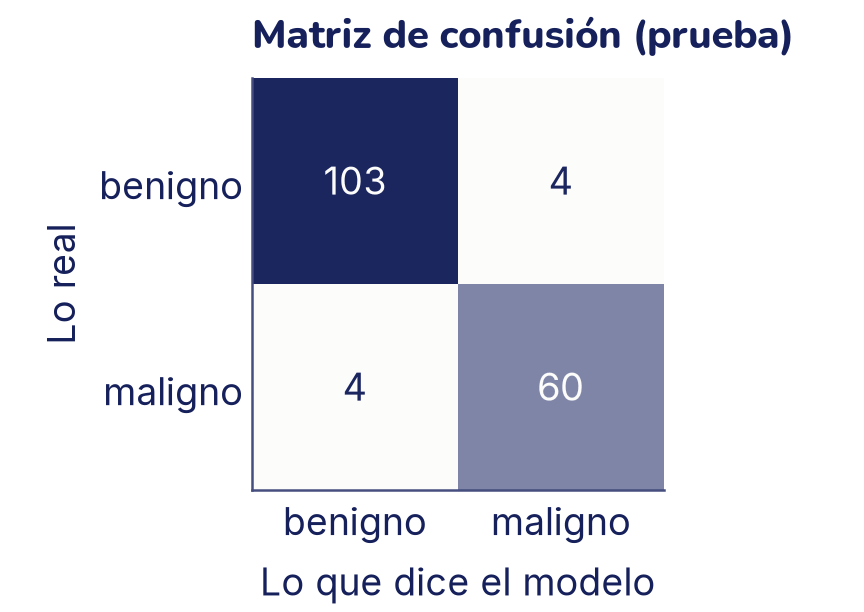

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay

datos = load_breast_cancer(as_frame=True)
X = datos.data
# En el original 1 = benigno; lo invertimos: 1 = maligno (positivo)
y = (datos.target == 0).astype(int)
print(f"{len(y)} tumores, {y.sum()} malignos ({y.mean():.0%})")

X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0)
escala = StandardScaler().fit(X_ent)
X_ent_e = escala.transform(X_ent)
X_prueba_e = escala.transform(X_prueba)

modelo = LogisticRegression().fit(X_ent_e, y_ent)
pred = modelo.predict(X_prueba_e)
print(confusion_matrix(y_prueba, pred))

ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred, display_labels=["benigno", "maligno"],
    cmap="Blues", colorbar=False)
plt.grid(False)
plt.xlabel("Lo que dice el modelo")
plt.ylabel("Lo real")
plt.title("Matriz de confusión (prueba)")
plt.show()

De 171 tumores de prueba, el modelo se equivocó con 8: marcó como malignos 4 tumores benignos (falsos positivos) y dejó pasar 4 malignos (falsos negativos). `classification_report` da todas las métricas de una vez, para cada clase:

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_prueba, pred,
                            target_names=["benigno", "maligno"]))

              precision    recall  f1-score   support

     benigno       0.96      0.96      0.96       107
     maligno       0.94      0.94      0.94        64

    accuracy                           0.95       171
   macro avg       0.95      0.95      0.95       171
weighted avg       0.95      0.95      0.95       171


Cada fila trata a esa clase como si fuera la positiva: la fila «maligno» es la que nos interesa. *support* es cuántos casos reales hay de esa clase. Las dos filas de abajo, los promedios, las vas a ver en la sección de varias clases. Una exhaustividad de 0,94 para «maligno» quiere decir que, de cada 100 tumores malignos, el modelo deja pasar unos 6. ¿Es aceptable? Eso no lo decide el modelo: lo decide el problema, y lo vas a poder ajustar con el umbral.

Un aviso importante, como en el tema 8: esto es un ejercicio de aprendizaje con un conjunto de datos público. Un modelo así no reemplaza el diagnóstico de un profesional de la salud.

## La trampa de la exactitud: clases desbalanceadas

Volvamos a la pregunta del inicio. Creamos con `make_classification` un problema sintético con 2000 casos donde cerca del 5 % es positivo (por ejemplo, transacciones fraudulentas), y comparamos tres modelos:

- un **modelo tonto**, `DummyClassifier`, que siempre responde la clase más frecuente sin mirar los datos;
- una regresión logística normal;
- una regresión logística con `class_weight="balanced"`, que en la pérdida le da más peso a cada error con la clase rara, como si hubiera tantos positivos como negativos.

Positivos: 110 de 2000 (5.5%)
            exactitud  precisión  exhaustividad     F1
tonto           0.945      0.000          0.000  0.000
logística       0.993      1.000          0.879  0.935
balanceada      0.977      0.721          0.939  0.816


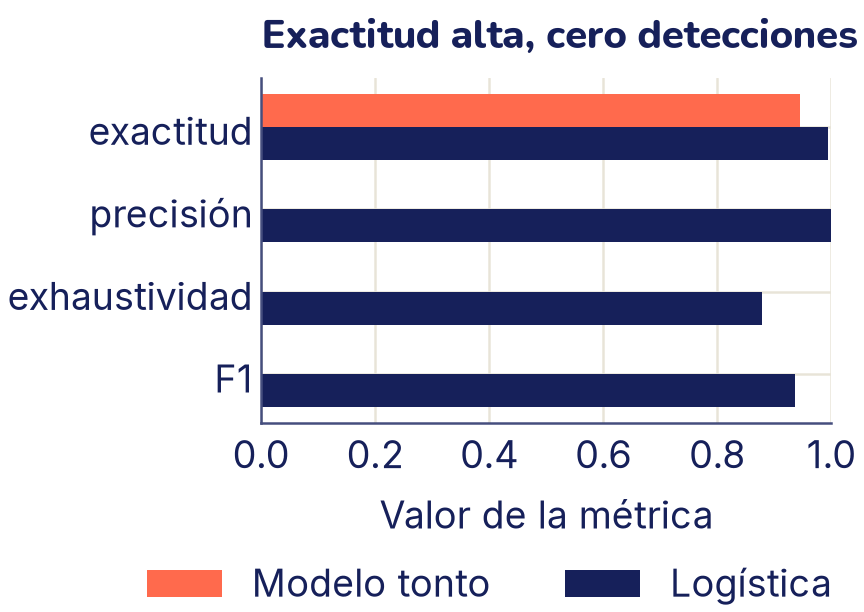

In [ ]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier

# weights=[0.95]: el 95 % de los casos son de la clase 0
X_d, y_d = make_classification(n_samples=2000, weights=[0.95],
                               random_state=0)
print(f"Positivos: {y_d.sum()} de {len(y_d)} ({y_d.mean():.1%})")
Xd_ent, Xd_prueba, yd_ent, yd_prueba = train_test_split(
    X_d, y_d, test_size=0.3, stratify=y_d, random_state=0)

modelos = {
    "tonto": DummyClassifier(strategy="most_frequent"),
    "logística": LogisticRegression(),
    "balanceada": LogisticRegression(class_weight="balanced"),
}
filas = {}
for nombre, mod in modelos.items():
    p = mod.fit(Xd_ent, yd_ent).predict(Xd_prueba)
    filas[nombre] = {
        "exactitud": accuracy_score(yd_prueba, p),
        # zero_division=0: si nunca dice «positivo», precisión 0
        "precisión": precision_score(yd_prueba, p, zero_division=0),
        "exhaustividad": recall_score(yd_prueba, p),
        "F1": f1_score(yd_prueba, p),
    }
tabla = pd.DataFrame(filas).T
print(tabla.round(3))

nombres = list(tabla.columns)[::-1]
pos = np.arange(len(nombres))
plt.barh(pos + 0.2, tabla.loc["tonto", nombres], height=0.4,
         color="C1", label="Modelo tonto")
plt.barh(pos - 0.2, tabla.loc["logística", nombres], height=0.4,
         color="C0", label="Logística")
plt.yticks(pos, nombres)
plt.xlim(0, 1)
plt.xlabel("Valor de la métrica")
plt.title("Exactitud alta, cero detecciones")
plt.legend(loc="upper center", bbox_to_anchor=(0.4, -0.3), ncol=2)
plt.show()

El modelo tonto tiene un 94,5 % de exactitud y **no encuentra ni un solo positivo**. Con clases desbalanceadas la exactitud se ve buena casi siempre, porque la dominan los negativos, que son la mayoría. Por eso:

- Compara siempre con el modelo tonto. Si tu modelo no le gana con claridad, no aprendió nada útil.
- Mira la precisión y la exhaustividad de la clase rara, no solo la exactitud.
- Divide con `stratify=y`: con solo 33 positivos en la prueba, una división al azar podría dejar muy pocos y las métricas variarían mucho.
- `class_weight="balanced"` cambia el equilibrio: aquí la exhaustividad sube de 0,879 a 0,939 (encuentra 31 de 33 en lugar de 29) a cambio de más falsas alarmas, y la precisión baja de 1 a 0,721. Ninguno de los dos es «el mejor»: depende de qué error cuesta más.

## El umbral es una decisión

`predict` usa el umbral 0,5: dice «positivo» si `predict_proba` da 0,5 o más. En el tema 8 ya viste que nada obliga a usar 0,5; ahora vamos a medir el efecto con las métricas. Si dejar pasar un tumor maligno es mucho peor que pedir una biopsia de más, conviene bajar el umbral para que el modelo marque más casos.

In [ ]:
proba = modelo.predict_proba(X_prueba_e)[:, 1]   # P(maligno)

for umbral in [0.5, 0.3, 0.1]:
    p = (proba >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_prueba, p).ravel()
    print(f"umbral {umbral}:  VP={vp} FN={fn} FP={fp} VN={vn}"
          f"   precisión={precision_score(y_prueba, p):.2f}"
          f"  exhaustividad={recall_score(y_prueba, p):.2f}")

umbral 0.5:  VP=60 FN=4 FP=4 VN=103   precisión=0.94  exhaustividad=0.94
umbral 0.3:  VP=61 FN=3 FP=10 VN=97   precisión=0.86  exhaustividad=0.95
umbral 0.1:  VP=63 FN=1 FP=14 VN=93   precisión=0.82  exhaustividad=0.98


Con el umbral en 0,1 se escapa un solo tumor maligno de 64, a cambio de 14 falsas alarmas en lugar de 4. Es el mismo modelo, con los mismos puntajes: lo único que cambió fue la decisión. `precision_recall_curve` prueba todos los umbrales posibles de una vez y devuelve la precisión y la exhaustividad de cada uno:

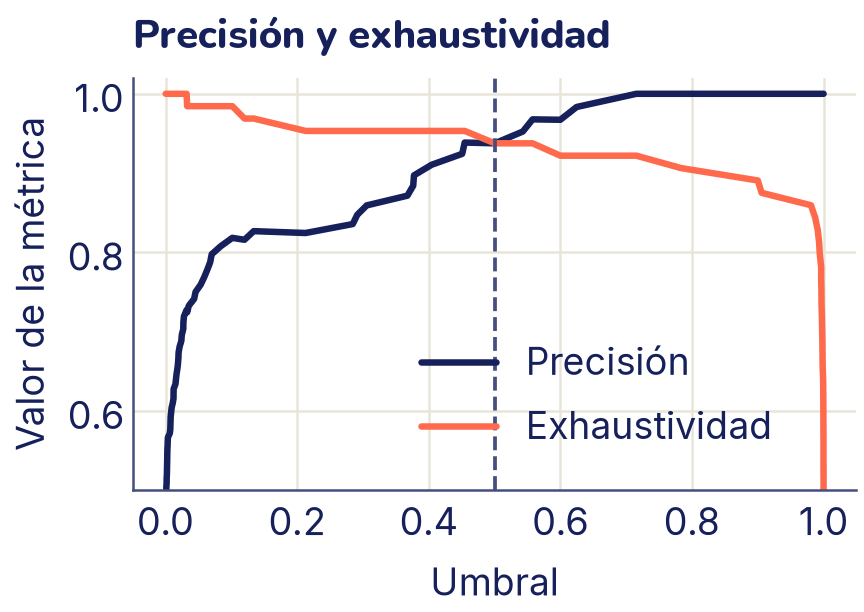

In [ ]:
from sklearn.metrics import precision_recall_curve

prec, exh, umbrales = precision_recall_curve(y_prueba, proba)

# prec y exh tienen un valor más que umbrales: se descarta el último
plt.plot(umbrales, prec[:-1], color="C0", label="Precisión")
plt.plot(umbrales, exh[:-1], color="C1", label="Exhaustividad")
plt.axvline(0.5, color="C2", linestyle="--", linewidth=1.5)
plt.xlabel("Umbral")
plt.ylabel("Valor de la métrica")
plt.ylim(0.5, 1.02)
plt.title("Precisión y exhaustividad")
plt.legend(loc="lower right", bbox_to_anchor=(0.93, 0.02))
plt.show()

Las dos métricas tiran en sentidos contrarios: subir el umbral hace al modelo más exigente, así que sus alarmas son más confiables (más precisión) pero encuentra menos casos (menos exhaustividad). Si en lugar del umbral pones la exhaustividad en el eje horizontal y la precisión en el vertical, tienes la **curva precisión–exhaustividad**, que muestra directamente cuánta precisión pierdes por cada caso más que encuentras.

## La curva ROC y el AUC

La curva **ROC** (del inglés *receiver operating characteristic*, un nombre que viene de los radares) es otra forma de ver todos los umbrales a la vez. Para cada umbral dibuja un punto:

- en el eje vertical, la **tasa de verdaderos positivos**: la exhaustividad, VP / (VP + FN);
- en el eje horizontal, la **tasa de falsos positivos**: qué fracción de los negativos recibió una falsa alarma, FP / (FP + VN).

Con el umbral en 1 el modelo no marca a nadie y el punto está en (0, 0). Con el umbral en 0 marca a todos y el punto está en (1, 1). Entre medio, la curva de un buen modelo sube casi vertical hacia la esquina de arriba a la izquierda: encuentra muchos positivos antes de dar falsas alarmas. Un modelo que adivina al azar queda sobre la diagonal.

El **AUC** (*area under the curve*) es el área bajo la curva ROC: 1 es perfecto y 0,5 es lo mismo que tirar una moneda. Comparemos nuestra logística con otra que solo mira una de las 30 medidas, la textura media del núcleo:

Textura: AUC = 0.810
30 medidas: AUC = 0.992


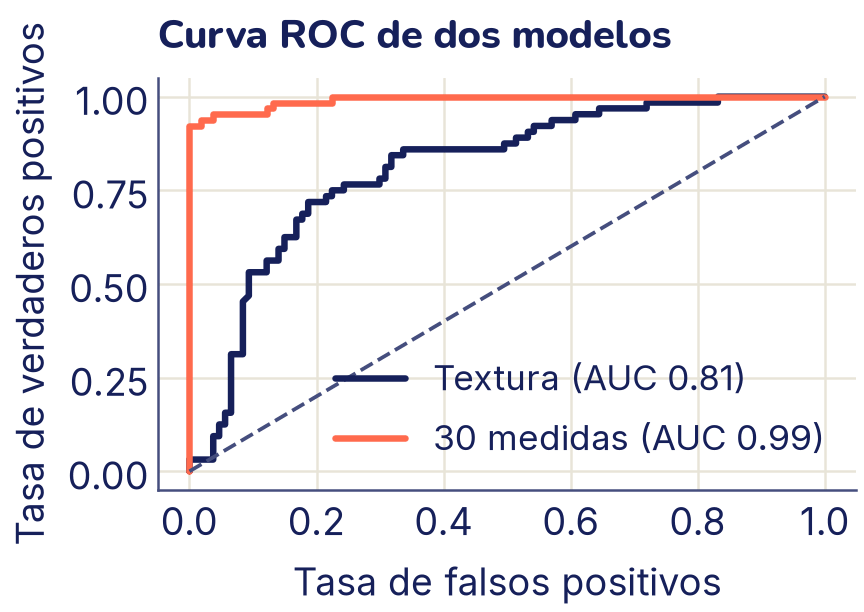

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Un modelo más débil: solo la columna «mean texture»
col = list(X.columns).index("mean texture")
debil = LogisticRegression().fit(X_ent_e[:, [col]], y_ent)
proba_debil = debil.predict_proba(X_prueba_e[:, [col]])[:, 1]

for nombre, pr, color in [("Textura", proba_debil, "C0"),
                          ("30 medidas", proba, "C1")]:
    tfp, tvp, _ = roc_curve(y_prueba, pr)
    auc = roc_auc_score(y_prueba, pr)
    print(f"{nombre}: AUC = {auc:.3f}")
    plt.plot(tfp, tvp, color=color, label=f"{nombre} (AUC {auc:.2f})")

plt.plot([0, 1], [0, 1], color="C2", linestyle="--", linewidth=1.5)
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC de dos modelos")
plt.legend(loc="lower right", fontsize=14)
plt.show()

El AUC tiene una lectura muy concreta: es la probabilidad de que, si tomas al azar un caso positivo y uno negativo, el modelo le dé **más puntaje al positivo**. Podemos comprobarlo comparando todos los pares:

In [ ]:
pos = proba[y_prueba == 1]          # puntajes de los malignos
neg = proba[y_prueba == 0]          # puntajes de los benignos
# Una tabla de 64 × 107: ¿el maligno tiene más puntaje que el benigno?
gana = pos[:, None] > neg[None, :]
empate = pos[:, None] == neg[None, :]
print(f"Pares comparados: {gana.size}")
print(f"AUC contando pares: {gana.mean() + 0.5 * empate.mean():.4f}")
print(f"AUC de scikit-learn: {roc_auc_score(y_prueba, proba):.4f}")

Pares comparados: 6848
AUC contando pares: 0.9917
AUC de scikit-learn: 0.9917


Por eso el AUC **no depende del umbral**: mide qué tan bien ordena el modelo a los casos, antes de decidir dónde cortar. Es una buena métrica para comparar modelos; pero para usar uno hay que elegir un punto de la curva, es decir, un umbral. Eso es lo que hiciste en la actividad al mover la línea: el AUC no cambiaba, la matriz de confusión sí.

Un aviso: con clases muy desbalanceadas la curva ROC puede verse muy bien aunque la precisión sea baja, porque la tasa de falsos positivos se divide entre muchísimos negativos. En la actividad lo viste al pasar a «1 de cada 10»: la curva no se movió, pero la precisión cayó. En esos casos conviene mirar también la curva precisión–exhaustividad.

## ¿Qué error cuesta más?

No hay una métrica correcta para todo. La pregunta es siempre la misma: **¿qué pasa cuando el modelo se equivoca de cada forma?**

- Si un **falso negativo** es grave (una enfermedad sin detectar, un incendio sin alarma), importa la **exhaustividad**: baja el umbral aunque aumenten las falsas alarmas.
- Si un **falso positivo** es grave (un correo importante que termina en la carpeta de basura, una persona inocente señalada), importa la **precisión**: sube el umbral.
- Si los dos errores importan parecido y las clases están desbalanceadas, **F1** es un buen resumen.
- La **exactitud** sirve cuando las clases están más o menos equilibradas y los dos errores cuestan lo mismo.
- Para comparar modelos sin haber elegido todavía un umbral, el **AUC**.

En la práctica se suele fijar una condición («no dejar pasar más del 5 % de los positivos») y, entre los umbrales que la cumplen, elegir el que da más precisión. Lo vas a hacer en el mini-proyecto.

## Más de dos clases: macro y micro

Con varias clases, la matriz de confusión tiene una fila y una columna por clase, y la precisión y la exhaustividad se calculan **para cada clase**, tratándola como la positiva y a todas las demás como negativas. Para resumirlas en un número hay dos maneras:

- **Promedio macro:** se calcula la métrica de cada clase y se promedian, todas con el mismo peso. Una clase rara pesa igual que una frecuente.
- **Promedio micro:** se juntan los VP, FP y FN de todas las clases y se calcula la métrica una sola vez. Pesan más las clases frecuentes. Cuando cada caso tiene una sola clase, la precisión, la exhaustividad y F1 micro son iguales a la exactitud.

`classification_report` muestra además el promedio *weighted*, que pondera cada clase por cuántos casos tiene. Veámoslo en un problema sintético con tres clases desbalanceadas:

In [ ]:
X3, y3 = make_classification(n_samples=1500, n_classes=3,
                             n_informative=4, weights=[0.8, 0.15, 0.05],
                             random_state=0)
X3_ent, X3_prueba, y3_ent, y3_prueba = train_test_split(
    X3, y3, test_size=0.3, stratify=y3, random_state=0)
p3 = LogisticRegression().fit(X3_ent, y3_ent).predict(X3_prueba)

print(confusion_matrix(y3_prueba, p3))
print(classification_report(y3_prueba, p3))
print(f"F1 macro: {f1_score(y3_prueba, p3, average='macro'):.3f}")
print(f"F1 micro: {f1_score(y3_prueba, p3, average='micro'):.3f}")

[[338  18   2]
 [ 34  30   5]
 [ 10   5   8]]
              precision    recall  f1-score   support

           0       0.88      0.94      0.91       358
           1       0.57      0.43      0.49        69
           2       0.53      0.35      0.42        23

    accuracy                           0.84       450
   macro avg       0.66      0.58      0.61       450
weighted avg       0.82      0.84      0.82       450

F1 macro: 0.609
F1 micro: 0.836


La exactitud (0,84) y el F1 micro dicen que el modelo va bastante bien, pero el F1 macro (0,61) avisa que con las clases 1 y 2 le va mal: de los 23 casos de la clase 2 solo encuentra 8. Si las clases raras son las que importan, el promedio macro es el que lo muestra.

## Diez clases: los dígitos del 0 al 9

Las tres clases sintéticas eran un ejemplo pequeño. Volvamos a los dígitos escritos a mano del tema 8: 1797 imágenes de 8 × 8 píxeles, con diez clases, una por dígito, y más o menos la misma cantidad de imágenes de cada uno. Esta vez hacemos las cosas como se deben hacer con datos de verdad, en **tres partes**: un 60 % para entrenar, un 20 % de **validación** para elegir el valor de `C` (el inverso de la fuerza de la regularización, tema 8) y un 20 % de **prueba**, que se usa una sola vez al final.

In [ ]:
from sklearn.datasets import load_digits

digitos = load_digits()
X10 = digitos.data / 16           # 64 píxeles entre 0 y 1, como en el tema 8
y10 = digitos.target              # el dígito, de 0 a 9
# 60 % para entrenar; el resto, mitad validación y mitad prueba
X10_ent, X10_resto, y10_ent, y10_resto = train_test_split(
    X10, y10, test_size=0.4, stratify=y10, random_state=0)
X10_val, X10_prueba, y10_val, y10_prueba = train_test_split(
    X10_resto, y10_resto, test_size=0.5, stratify=y10_resto,
    random_state=0)
print(len(y10_ent), "para entrenar,", len(y10_val), "de validación y",
      len(y10_prueba), "de prueba")

for C in [0.1, 1, 10, 100]:
    m = LogisticRegression(C=C, max_iter=1000).fit(X10_ent, y10_ent)
    print(f"C = {C:5}: exactitud en validación "
          f"{m.score(X10_val, y10_val):.3f}")

1078 para entrenar, 359 de validación y 360 de prueba
C =   0.1: exactitud en validación 0.939
C =     1: exactitud en validación 0.978
C =    10: exactitud en validación 0.981
C =   100: exactitud en validación 0.975


Elegimos `C = 10`, el mejor en la validación. Ahora sí, una sola vez, la prueba. Buscamos además la **confusión más frecuente**, el número más grande fuera de la diagonal, para resaltarla en la figura:

[[35  0  0  0  0  0  0  0  0  0]
 [ 0 35  0  0  0  0  0  0  1  1]
 [ 0  1 34  0  0  0  0  0  0  0]
 [ 0  0  0 36  0  1  0  0  0  0]
 [ 0  1  0  0 34  0  0  0  1  0]
 [ 0  0  0  0  0 35  1  1  0  0]
 [ 0  0  0  0  0  0 36  0  0  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  2  0  0  0  0  0  0 33  0]
 [ 0  0  0  0  0  1  0  0  0 35]]
Confusión más frecuente: un 8 leído como 1, 2 veces


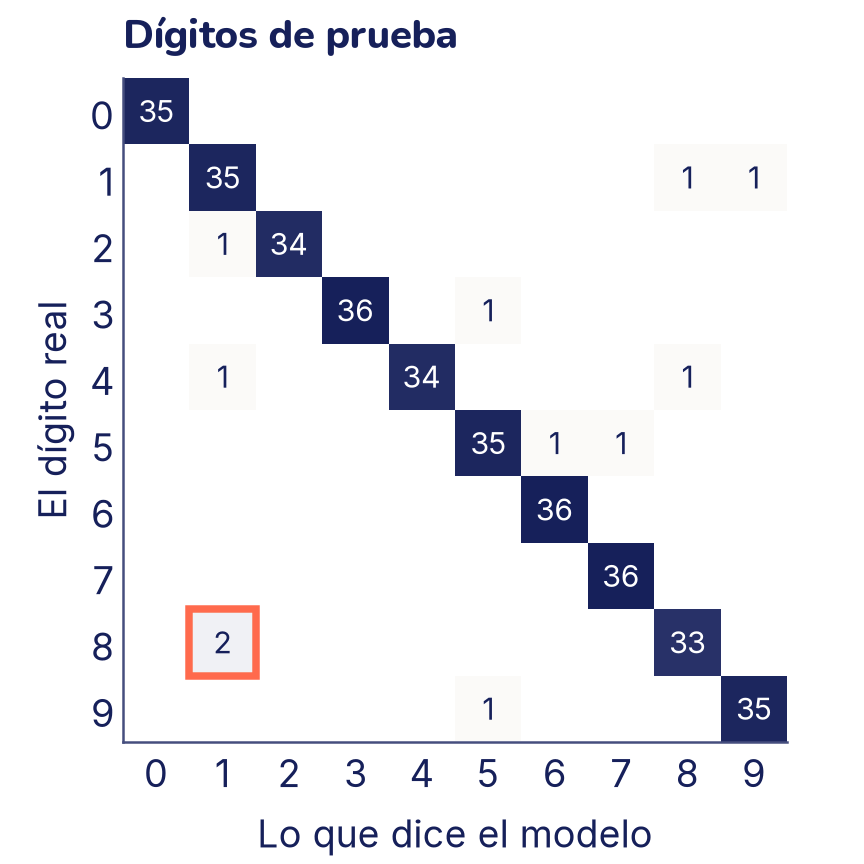

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

log10 = LogisticRegression(C=10, max_iter=1000).fit(X10_ent, y10_ent)
pred10 = log10.predict(X10_prueba)        # la prueba, una sola vez
cm10 = confusion_matrix(y10_prueba, pred10)
print(cm10)

errores10 = cm10.copy()
np.fill_diagonal(errores10, 0)            # borra los aciertos
# argmax da la posición en la tabla aplanada; unravel_index la
# convierte en (fila, columna)
fila, col = np.unravel_index(errores10.argmax(), errores10.shape)
print(f"Confusión más frecuente: un {fila} leído como {col},"
      f" {errores10[fila, col]} veces")

# Escala de blanco a tinta, como en el tema 8
blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
fig, eje = plt.subplots(figsize=(4.8, 4.8))
disp = ConfusionMatrixDisplay(cm10).plot(
    ax=eje, cmap=blanco_tinta, colorbar=False, text_kw={"fontsize": 12})
# Solo para dibujar: ocultar los ceros y marcar la confusión
for texto in disp.text_.ravel():
    if texto.get_text() == "0":
        texto.set_text("")
eje.add_patch(Rectangle((col - 0.5, fila - 0.5), 1, 1, fill=False,
                        edgecolor="C1", linewidth=3))
eje.grid(False)
eje.set_xlabel("Lo que dice el modelo")
eje.set_ylabel("El dígito real")
eje.set_title("Dígitos de prueba")
plt.show()

Cómo se lee una matriz de 10 × 10:

- **La diagonal son los aciertos.** La celda de la fila 3 y la columna 3 cuenta los treses que el modelo leyó como 3 (36). Si todo saliera bien, todo lo demás estaría vacío.
- **Cada fila es un dígito real.** La fila del 8 suma los 35 ochos de la prueba: 33 bien leídos, 2 leídos como 1. Lo que falta en la diagonal de una fila son los **falsos negativos** de ese dígito, y la fila da su exhaustividad: 33 / 35.
- **Cada columna es lo que dijo el modelo.** La columna del 1 junta todas las veces que dijo «1»: 35 eran unos y 4 no. Esos 4 son los **falsos positivos** del 1, y la columna da su precisión: 35 / 39.

Los errores son pocos (11 de 360) y por eso cada celda tiene 1 o 2 casos: con tan pocos, no conviene sacar conclusiones firmes de un par en particular. Aun así hay un patrón: el 1 y el 8 se confunden en las dos direcciones (2 ochos leídos como 1 y un 1 leído como 8), y el 1 recibe errores de varios dígitos. Una explicación posible: en 8 × 8 píxeles, un 8 escrito angosto se vuelve casi una columna de tinta, como un 1, y muchos unos de este dataset tienen un trazo arriba y una base abajo que se parecen a las curvas de un 8. Otras confusiones, como un 3 leído como 5 o un 5 leído como 6, también tienen sentido: el 3 y el 5 comparten la curva de abajo, y al 5 le falta poco para cerrarse como un 6. Para saberlo de verdad, hay que **mirar las imágenes** que falla, como hiciste en el tema 8.

El reporte por dígito da una fila por clase:

In [ ]:
print(classification_report(y10_prueba, pred10))

# average=None: una exhaustividad por clase, sin promediar
exh10 = recall_score(y10_prueba, pred10, average=None)
peor = exh10.argmin()
print(f"Exactitud global:   {accuracy_score(y10_prueba, pred10):.3f}")
print(f"Peor exhaustividad: {exh10[peor]:.3f} (el dígito {peor})")

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        35
           1       0.90      0.95      0.92        37
           2       1.00      0.97      0.99        35
           3       1.00      0.97      0.99        37
           4       1.00      0.94      0.97        36
           5       0.95      0.95      0.95        37
           6       0.97      1.00      0.99        36
           7       0.97      1.00      0.99        36
           8       0.94      0.94      0.94        35
           9       0.97      0.97      0.97        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360

Exactitud global:   0.969
Peor exhaustividad: 0.943 (el dígito 8)


Aquí las clases están equilibradas, así que los promedios macro, ponderado y la exactitud casi coinciden: a diferencia del problema de tres clases, ninguna clase rara queda escondida en el promedio. Pero un promedio sigue siendo un promedio: la exactitud global es de 0,969 y la exhaustividad del 8 es de 0,943. Se le escapan 2 de cada 35 ochos, casi un 6 %, el doble del 3 % de errores que sugiere la exactitud. Si el modelo leyera montos de cheques o códigos postales, el dígito que peor lee es justamente el que hay que mirar, y eso lo dice la fila de la matriz o del reporte, no la exactitud.

Por último, veamos de dónde sale cada predicción. Con más de dos clases, `LogisticRegression` usa **softmax** (tema 8): un puntaje por dígito, convertido en diez probabilidades que suman 1, y la predicción es el dígito con la probabilidad más alta. Tomamos el caso de prueba en el que el modelo está **menos seguro**:

In [ ]:
proba10 = log10.predict_proba(X10_prueba)     # una fila por imagen
# La probabilidad del dígito elegido, para cada imagen
seguridad = proba10.max(axis=1)
i = seguridad.argmin()                        # el caso más dudoso
print("Probabilidades, del 0 al 9:")
print(np.round(proba10[i], 3))
print(f"Suman {proba10[i].sum():.3f}; la mayor es la del",
      proba10[i].argmax(), "  predict dice", pred10[i],
      "  y era un", y10_prueba[i])

Probabilidades, del 0 al 9:
[0.002 0.287 0.    0.    0.086 0.01  0.013 0.054 0.213 0.337]
Suman 1.000; la mayor es la del 9   predict dice 9   y era un 9


Acertó, pero por poco: le dio 0,337 al 9, 0,287 al 1 y 0,213 al 8, y el resto casi nada. Con `predict` solo verías «9»; con `predict_proba` ves que el modelo dudaba entre tres dígitos. Esas probabilidades son las que miden la log-loss y la calibración de las secciones que siguen, ahora con diez clases en lugar de dos.

## Medir las probabilidades: log-loss

Todas las métricas anteriores, salvo el AUC, miran la decisión final. Pero dos modelos que deciden igual pueden dar probabilidades muy distintas: uno dice 0,51 y el otro 0,99. La **log-loss** (pérdida logarítmica) es la entropía cruzada del tema 8 usada como métrica: castiga mucho a un modelo que da una probabilidad alta a la clase equivocada. Cuanto más baja, mejor.

In [ ]:
from sklearn.metrics import log_loss

print(f"Log-loss, 30 medidas:      {log_loss(y_prueba, proba):.3f}")
print(f"Log-loss, solo la textura: {log_loss(y_prueba, proba_debil):.3f}")
# Un modelo que siempre dice «la proporción de malignos»
base = np.full(len(y_prueba), y_ent.mean())
print(f"Log-loss, sin mirar nada:  {log_loss(y_prueba, base):.3f}")

Log-loss, 30 medidas:      0.107
Log-loss, solo la textura: 0.548
Log-loss, sin mirar nada:  0.661


El modelo de 30 medidas no solo acierta más: además está muy seguro cuando acierta y rara vez está seguro cuando se equivoca, por eso su log-loss es tan baja. El que solo mira la textura queda entre él y el que no mira nada, que siempre dice «37 % de probabilidad de maligno».

Y si el problema no es de clasificación sino de regresión (predecir un número), las métricas son las del tema 6: el **MAE** y el **RMSE**, en las unidades del objetivo, y el **R²**, que compara con el modelo que siempre predice el promedio. La idea es la misma: compararse siempre con un modelo tonto.

## ¿Se puede creer en un 80 %? Calibración

Piensa en alguien que pronostica el tiempo y cada noche dice la probabilidad de que llueva al día siguiente. Si juntas todos los días en que dijo «80 %», ¿en cuántos llovió? Si llovió en unos 8 de cada 10, sus probabilidades son **creíbles**: cuando dice 80 %, quiere decir 80 %. De un modelo así se dice que está **bien calibrado**. Si en esos días llovió solo la mitad de las veces, exagera su seguridad, aunque sepa muy bien qué días son los más lluviosos.

Es una pregunta distinta de las anteriores. El AUC mide si el modelo **ordena** bien a los casos; la calibración mide si sus puntajes se pueden **leer como probabilidades**. Un modelo puede ordenar casi perfecto y aun así decir «99 %» cuando debería decir «70 %». Importa cada vez que la probabilidad se usa como número: para decirle a una persona «tienes un 30 % de riesgo», para calcular cuánto se espera perder o ganar, o para elegir un umbral según el costo de cada error.

### El diagrama de fiabilidad y el puntaje de Brier

Para revisar la calibración se agrupan los casos según la probabilidad que dijo el modelo, en **intervalos** (de 0 a 0,1, de 0,1 a 0,2, y así), y en cada intervalo se compara el promedio de lo que dijo con la fracción de positivos que hubo de verdad. Cada intervalo da un punto. Si el modelo está bien calibrado, los puntos quedan sobre la diagonal: cuando dijo 0,8, hubo un 80 % de positivos. Ese gráfico se llama **diagrama de fiabilidad** (*reliability diagram*) y `calibration_curve` calcula sus puntos.

Para tener un solo número se usa el **puntaje de Brier** (*Brier score*). La idea: en cada caso, mira cuánto se alejó la probabilidad *p* de lo que pasó (*y* = 1 si fue positivo, 0 si no), eleva esa diferencia al cuadrado y promedia sobre los *n* casos. Es el error cuadrático medio del tema 6, aplicado a probabilidades:

$$\text{Brier} = \frac{1}{n} \sum_{i = 1}^{n} {( {p}_{i} - {y}_{i} )}^{2}$$

Va de 0 (perfecto) a 1, y cuanto más bajo, mejor; un modelo que siempre dice 0,5 saca 0,25. Como la log-loss, mira las probabilidades y no solo la decisión, pero castiga menos los errores extremos: decir «100 %» y equivocarse le suma 1 al Brier de ese caso, mientras que en la log-loss el castigo no tiene techo.

Para ver la calibración hacen falta muchos casos: con los 171 tumores de prueba, cada intervalo tendría unos pocos y los puntos saltarían por puro azar. Por eso usamos un problema sintético de 6000 casos, más o menos la mitad de cada clase, dividido en **tres partes**: la mitad para **ajustar** los modelos, un cuarto para **calibrarlos** y el último cuarto para la **prueba**, que se usa una sola vez al final. Comparamos la regresión logística con el k-NN del tema 8 con k = 5. El k-NN da como probabilidad la fracción de sus 5 vecinos que son positivos, así que solo puede decir 0, 0,2, 0,4, 0,6, 0,8 o 1.

El k-NN solo dice: [0.  0.2 0.4 0.6 0.8 1. ]
Cuando dice 0, eran positivos: 6.2%
Cuando dice 1, eran positivos: 96.8%
Logística: Brier 0.114   log-loss 0.375
k-NN, k = 5: Brier 0.119   log-loss 1.106


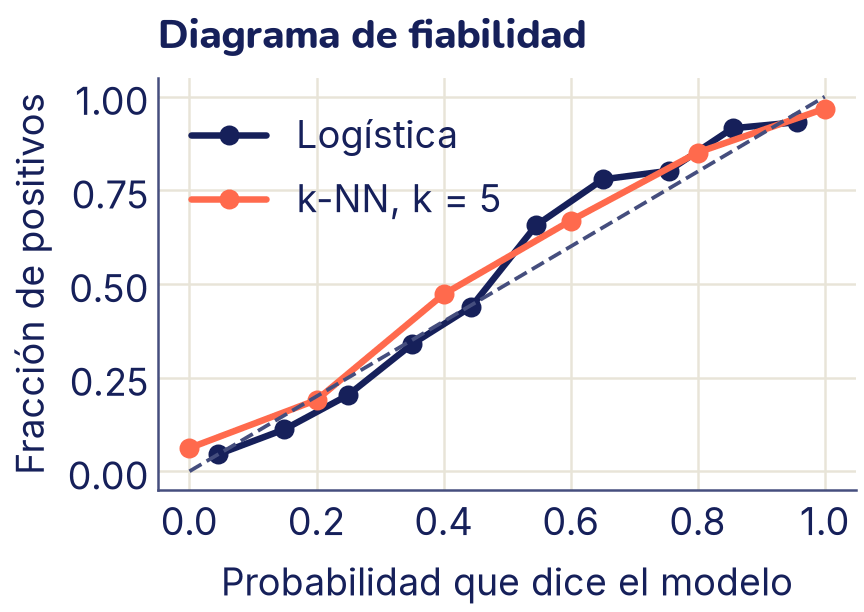

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

Xc, yc = make_classification(n_samples=6000, n_informative=5,
                             random_state=0)
# Mitad para ajustar; el resto, mitad para calibrar y mitad para prueba
Xc_aj, Xc_resto, yc_aj, yc_resto = train_test_split(
    Xc, yc, test_size=0.5, random_state=0)
Xc_cal, Xc_prueba, yc_cal, yc_prueba = train_test_split(
    Xc_resto, yc_resto, test_size=0.5, random_state=0)

log_c = LogisticRegression().fit(Xc_aj, yc_aj)
knn_c = KNeighborsClassifier(n_neighbors=5).fit(Xc_aj, yc_aj)
p_log = log_c.predict_proba(Xc_cal)[:, 1]
p_knn = knn_c.predict_proba(Xc_cal)[:, 1]
# np.unique: los valores distintos, de menor a mayor
print("El k-NN solo dice:", np.unique(p_knn))
for v in [0, 1]:
    print(f"Cuando dice {v}, eran positivos: "
          f"{yc_cal[p_knn == v].mean():.1%}")

for nombre, p, color in [("Logística", p_log, "C0"),
                         ("k-NN, k = 5", p_knn, "C1")]:
    print(f"{nombre}: Brier {brier_score_loss(yc_cal, p):.3f}"
          f"   log-loss {log_loss(yc_cal, p):.3f}")
    # Devuelve primero lo real y después lo que dijo el modelo
    real, dicho = calibration_curve(yc_cal, p, n_bins=10)
    plt.plot(dicho, real, marker="o", color=color, label=nombre)

plt.plot([0, 1], [0, 1], color="C2", linestyle="--", linewidth=1.5)
plt.xlabel("Probabilidad que dice el modelo")
plt.ylabel("Fracción de positivos")
plt.title("Diagrama de fiabilidad")
plt.legend(loc="upper left")
plt.show()

A simple vista las dos curvas se parecen. La logística queda cerca de la diagonal: suele salir bien calibrada porque se entrena justamente minimizando la log-loss. El problema del k-NN está en las puntas, y se ve mejor en los números que en el dibujo: cuando dice 0 %, el 6,2 % de esos casos era positivo, y cuando dice 100 %, el 3,2 % no lo era. Está **demasiado seguro**: con solo 5 vecinos, que los 5 sean de la misma clase pasa seguido aunque el caso no sea tan claro. El Brier del k-NN es apenas peor que el de la logística (0,119 contra 0,114), pero su log-loss es casi el triple (1,106 contra 0,375): cada «0 %» o «100 %» equivocado le cuesta muchísimo. (En teoría el castigo sería infinito; scikit-learn recorta las probabilidades un poquito antes de 0 y de 1 para que dé un número.)

### Calibrar: corregir las probabilidades después de entrenar

**Calibrar** es aprender una función que traduce lo que dice el modelo a una probabilidad creíble, algo como «cuando el k-NN dice 1, en realidad es 0,96». `CalibratedClassifierCV` tiene dos maneras de hacerlo:

- **Sigmoide** (o método de Platt): ajusta una pequeña regresión logística que recibe el puntaje del modelo como única entrada. Tiene solo dos parámetros, así que funciona con pocos datos, pero supone que la corrección tiene forma de S.
- **Isotónica**: ajusta una escalera que solo sube (a más puntaje, más probabilidad, nunca menos). Se adapta a cualquier forma, pero necesita más datos: con pocos casos se sobreajusta (tema 7).

La función se aprende con **datos que el modelo no vio al entrenar**: la parte de calibración. Si calibraras con los datos de entrenamiento, el calibrador vería al modelo en su mejor día (el k-NN, por ejemplo, tiene a cada caso de entrenamiento como su propio vecino, así que ahí acierta de más) y aprendería a confiar demasiado. Es la misma trampa que medir un modelo con sus datos de entrenamiento; en el tema 10 la vas a ver con su nombre, **fuga de datos**, y en el ejercicio 7 la vas a medir.

`FrozenEstimator` («estimador congelado») envuelve al k-NN ya entrenado para que `CalibratedClassifierCV` lo use tal cual y aprenda solo la corrección con los datos que le damos. Al final medimos todo una sola vez con la prueba:

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

modelos_c = {"logística": log_c, "k-NN": knn_c}
for metodo in ["sigmoid", "isotonic"]:
    cal = CalibratedClassifierCV(FrozenEstimator(knn_c), method=metodo)
    modelos_c[f"k-NN {metodo}"] = cal.fit(Xc_cal, yc_cal)

filas = {}
for nombre, mod in modelos_c.items():
    p = mod.predict_proba(Xc_prueba)[:, 1]
    filas[nombre] = {
        "Brier": brier_score_loss(yc_prueba, p),
        "log-loss": log_loss(yc_prueba, p),
        "exactitud": accuracy_score(yc_prueba, p >= 0.5),
        "AUC": roc_auc_score(yc_prueba, p),
    }
print(pd.DataFrame(filas).T.round(3))

               Brier  log-loss  exactitud    AUC
logística      0.118     0.383      0.841  0.912
k-NN           0.121     1.268      0.841  0.905
k-NN sigmoid   0.118     0.383      0.841  0.905
k-NN isotonic  0.118     0.385      0.841  0.905


Después de calibrar, el Brier y la log-loss del k-NN bajan hasta los de la logística (0,118 y 0,383 con la sigmoide; 0,118 y 0,385 con la isotónica). Lo que más cambió es la log-loss, que deja de dispararse porque el k-NN calibrado ya no dice 0 ni 1. En cambio, la **exactitud y el AUC no cambian**. Las dos correcciones son funciones que solo suben: el caso que tenía más puntaje sigue teniendo más (la isotónica, a lo sumo, junta algunos en un mismo escalón), así que el orden se mantiene, y el AUC solo mira el orden. La exactitud tampoco cambió porque aquí el corte en 0,5 sigue separando los mismos casos; en otros problemas puede moverse un poco. Calibrar no hace más listo al modelo: le enseña a decir con honestidad cuánto sabe.

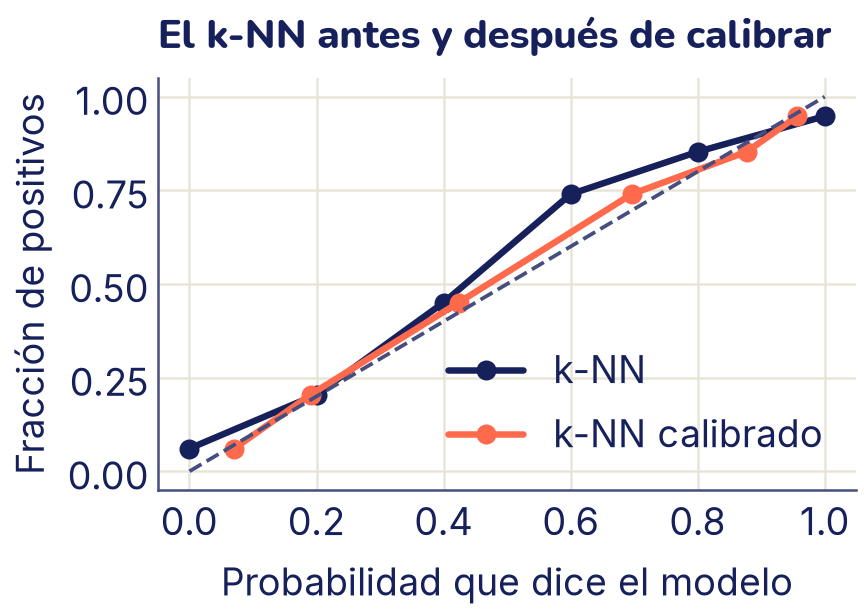

In [ ]:
p_sig = modelos_c["k-NN sigmoid"].predict_proba(Xc_prueba)[:, 1]
p_knn_prueba = knn_c.predict_proba(Xc_prueba)[:, 1]
for nombre, p, color in [("k-NN", p_knn_prueba, "C0"),
                         ("k-NN calibrado", p_sig, "C1")]:
    real, dicho = calibration_curve(yc_prueba, p, n_bins=10)
    plt.plot(dicho, real, marker="o", color=color, label=nombre)
plt.plot([0, 1], [0, 1], color="C2", linestyle="--", linewidth=1.5)
plt.xlabel("Probabilidad que dice el modelo")
plt.ylabel("Fracción de positivos")
plt.title("El k-NN antes y después de calibrar")
plt.legend(loc="lower right")
plt.show()

Cada punto calibrado tiene la misma altura que antes (son los mismos casos), pero se corrió hacia donde debía estar: lo que el k-NN llamaba «0 %» ahora se llama 7 %, y su «100 %» ahora es un 96 %.

Dos cosas más. Si no quieres apartar una parte para calibrar, `CalibratedClassifierCV(KNeighborsClassifier(n_neighbors=5), cv=5)` hace la separación por dentro: entrena cinco modelos con validación cruzada y calibra cada uno con el pliegue que no vio. Y no todos los modelos la necesitan igual: la logística suele salir bien calibrada, mientras que el k-NN, los árboles y sus ensambles (tema 11), las SVM (tema 12) y las redes neuronales grandes suelen necesitarla: unos se pasan de seguros y otros se quedan cortos. Para las redes hay un truco propio, el escalado de temperatura, que verás en el tema 19.

## Pérdidas y métricas: el mapa

En la ruta aparecen dos clases de números para juzgar un modelo, y conviene no mezclarlas:

- La **función de pérdida** es lo que el modelo **minimiza al entrenar**. El descenso de gradiente del tema 6 necesita saber hacia dónde bajar, así que la pérdida tiene que poder **derivarse**: cambiar un poco los pesos tiene que cambiarla un poco. Se permite alguna esquina (la bisagra y el MAE tienen una), porque ahí basta con elegir la pendiente de uno de los lados, el subgradiente del tema 12.
- La **métrica** es lo que a nosotros nos **importa medir**, para decidir si el modelo sirve. No necesita poder derivarse: solo hay que poder calcularla.

La exactitud es el ejemplo clásico de métrica que no sirve como pérdida. Si mueves un poquito los pesos de la regresión logística, casi ninguna probabilidad cruza el 0,5 y la exactitud no cambia nada: va a saltos y su pendiente es cero casi en todas partes, así que el descenso de gradiente no sabría hacia dónde ir. Por eso se entrena con una pérdida suave que empuja en la dirección correcta, la entropía cruzada, y se informa la métrica que importa. Es lo que pasó con los dígitos: `LogisticRegression` minimizó la entropía cruzada (más la regularización) y nosotros informamos la exactitud y la exhaustividad de cada dígito.

In [ ]:
# Lo que el modelo minimizó al entrenar y lo que informamos
print(f"Entropía cruzada (log-loss) en la prueba: "
      f"{log_loss(y10_prueba, proba10):.3f}")
print(f"Exactitud en la prueba: "
      f"{accuracy_score(y10_prueba, pred10):.3f}")

Entropía cruzada (log-loss) en la prueba: 0.100
Exactitud en la prueba: 0.969


Los dos números miran al mismo modelo con preguntas distintas: la entropía cruzada pregunta «¿cuánta probabilidad le diste a la respuesta correcta?», y la exactitud, «¿cuántas veces acertaste?». Algunas pérdidas, como la entropía cruzada, también se usan como métricas (ahí la llamamos log-loss); la mayoría de las métricas, como la exactitud, F1 o el AUC, no se usan como pérdidas.

Estas son las **pérdidas** que aparecen en la ruta:

| Pérdida | Cuándo se usa | Dónde |
| --- | --- | --- |
| **MSE**, error cuadrático medio | Regresión. Castiga mucho los errores grandes y es suave, sin esquinas. Es la de la regresión lineal y la de `nn.MSELoss`. | [Tema 6](https://iabolivia.org/ruta/6-regresion-lineal-y-descenso-de-gradiente/teoria/) y [tema 18](https://iabolivia.org/ruta/18-pytorch-tensores-autograd-y-el-bucle-de-entrenamiento/teoria/) |
| **MAE**, error absoluto medio | Regresión con atípicos: trata todos los errores por igual. Tiene una esquina en el cero; en la ruta la usamos sobre todo como métrica. | [Tema 6](https://iabolivia.org/ruta/6-regresion-lineal-y-descenso-de-gradiente/teoria/) |
| **Entropía cruzada binaria** (log-loss) | Dos clases, con la sigmoide: la regresión logística. Castiga sin límite estar seguro de algo falso. | [Tema 8](https://iabolivia.org/ruta/8-clasificar-vecinos-cercanos-y-regresion-logistica/teoria/); como métrica, este tema |
| **Entropía cruzada categórica**, con softmax | Varias clases: la logística con softmax y las redes que clasifican (`nn.CrossEntropyLoss`, que recibe logits). | [Tema 8](https://iabolivia.org/ruta/8-clasificar-vecinos-cercanos-y-regresion-logistica/teoria/) y [tema 18](https://iabolivia.org/ruta/18-pytorch-tensores-autograd-y-el-bucle-de-entrenamiento/teoria/) |
| **Bisagra** (*hinge*) | La SVM. Vale cero desde *y*·*z* = 1, así que solo los vectores de soporte mueven la frontera. | [Tema 12](https://iabolivia.org/ruta/12-maquinas-de-vectores-de-soporte/teoria/) |
| **Brier** | Es el MSE aplicado a probabilidades. Aquí la usamos como métrica de calibración; como es suave, también se podría minimizar. | Este tema |

Y estas, las **métricas**, según el tipo de problema:

| Problema | Métrica | Cuándo conviene | Dónde |
| --- | --- | --- | --- |
| Regresión | **MAE** | El error típico en las unidades del problema («me equivoco por tantos puntos»), sin que pocos atípicos lo dominen. | [Tema 6](https://iabolivia.org/ruta/6-regresion-lineal-y-descenso-de-gradiente/teoria/) |
| Regresión | **RMSE** | También en unidades, pero pesa más los errores grandes: cuando uno grande es grave. | [Tema 6](https://iabolivia.org/ruta/6-regresion-lineal-y-descenso-de-gradiente/teoria/) |
| Regresión | **R²** | Comparar con el modelo que siempre predice el promedio, sin unidades: 1 es perfecto y 0 no es mejor que el promedio. | [Tema 6](https://iabolivia.org/ruta/6-regresion-lineal-y-descenso-de-gradiente/teoria/) |
| Clasificación | **Exactitud** (tasa de aciertos) | Clases más o menos equilibradas y errores que cuestan lo mismo. | [Tema 8](https://iabolivia.org/ruta/8-clasificar-vecinos-cercanos-y-regresion-logistica/teoria/) y este tema |
| Clasificación | **Precisión** | Cuando una falsa alarma es cara. | Este tema |
| Clasificación | **Exhaustividad** | Cuando dejar pasar un positivo es caro. | Este tema |
| Clasificación | **F1** | Las dos importan y la clase positiva es rara. | Este tema |
| Clasificación | **AUC** | Comparar modelos por cómo ordenan los casos, antes de elegir un umbral. | Este tema |
| Clasificación | **Log-loss** | Cuando las probabilidades importan: castiga mucho estar seguro y equivocarse. | Este tema |
| Clasificación | **Brier** | Revisar si las probabilidades son creíbles, con un castigo más moderado que la log-loss. | Este tema |
| Varias clases | **Macro** | Todas las clases pesan igual: cuando las clases raras importan. | Este tema |
| Varias clases | **Micro** | Cada caso pesa igual; con una sola clase por caso, es la exactitud. | Este tema |
| Varias clases | **Ponderado** (*weighted*) | Cada clase pesa según cuántos casos tiene. | Este tema |

La regla para elegir: la **pérdida** la decide el tipo de modelo y de salida (un número, dos clases, varias clases), y casi siempre viene ya puesta. La **métrica** la decide el problema real, con la pregunta de la sección «¿Qué error cuesta más?», y tiene que quedar elegida **antes** de mirar la prueba.

## Lo que aprendiste y lo que sigue

- La **matriz de confusión** cuenta los cuatro resultados posibles: verdaderos positivos y negativos (aciertos) y falsos positivos y negativos (errores). En scikit-learn, las filas son lo real y las columnas, lo predicho.
- La **exactitud** mide los aciertos en total; la **precisión**, cuánto confiar en una alarma; la **exhaustividad**, cuántos positivos se encuentran; **F1** combina las dos últimas.
- Con **clases desbalanceadas** la exactitud engaña: un modelo tonto puede tener 95 % sin servir para nada. Compárate con él, estratifica al dividir y mira las métricas de la clase rara.
- El **umbral** es una decisión: bajarlo sube la exhaustividad y baja la precisión. Se elige según el costo de cada error.
- La **curva ROC** muestra todos los umbrales a la vez y el **AUC** mide qué tan bien ordena el modelo a los casos, sin depender del umbral.
- Con varias clases, el promedio **macro** trata igual a todas y el **micro** se deja llevar por las frecuentes. En una matriz de 10 × 10, la diagonal son los aciertos y cada fila es una clase real; aunque la exactitud sea alta, mira la exhaustividad de la clase que peor se reconoce. `predict_proba` da una probabilidad por clase, que suman 1, y la predicción es la mayor.
- Un modelo está **bien calibrado** si, cuando dice 80 %, acierta el 80 % de las veces. El **diagrama de fiabilidad** y el **puntaje de Brier** lo revisan, y `CalibratedClassifierCV` (sigmoide o isotónica) corrige las probabilidades con datos que el modelo no vio, sin cambiar el orden de los casos.
- La **pérdida** es lo que el modelo minimiza al entrenar y tiene que poder derivarse; la **métrica** es lo que importa medir y puede no poder derivarse. Se entrena con entropía cruzada y se informa, por ejemplo, la exactitud o F1.

En el tema 10 vas a preparar los datos antes de entrenar (limpiarlos, transformar variables y armar *pipelines*) sin hacerte trampa, y desde ahí todos los modelos que veas se van a medir con las herramientas de este tema.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables de la teoría: `X_ent`, `X_prueba`, `y_ent`, `y_prueba` (los tumores), `proba` (los puntajes de la regresión logística en la prueba), `y3_prueba` y `p3` (el problema de tres clases), `cm10`, `y10_prueba` y `pred10` (los dígitos), `knn_c`, `Xc_aj`, `Xc_cal`, `Xc_prueba` y `modelos_c` (la calibración), además de las funciones de `sklearn.metrics` que importamos allí. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. Métricas a mano

Un filtro de correo basura se probó con 1000 correos (cifras inventadas para el ejercicio). La clase positiva es «basura». Esta es su matriz de confusión:

| | Dice «normal» | Dice «basura» |
|---|---|---|
| **Real: normal** | 850 | 10 |
| **Real: basura** | 40 | 100 |

a) ¿Cuántos son VP, FP, VN y FN?

b) Calcula sin computadora la exactitud, la precisión, la exhaustividad y F1.

c) Explica con una frase, sin usar los nombres de las métricas, qué quiere decir la precisión en este problema, y otra para la exhaustividad.

<details>
<summary>Respuesta</summary>

a) VN = 850 (correos normales que llegan a la bandeja), FP = 10 (correos normales mandados a la basura), FN = 40 (basura que se coló) y VP = 100 (basura atrapada).

b)

- Exactitud = (100 + 850) / 1000 = **0,95**
- Precisión = 100 / (100 + 10) = 100 / 110 ≈ **0,909**
- Exhaustividad = 100 / (100 + 40) = 100 / 140 ≈ **0,714**
- F1 = 2 · 0,909 · 0,714 / (0,909 + 0,714) ≈ **0,8**

c) Precisión: de cada 11 correos que el filtro manda a la basura, 10 eran basura de verdad. Exhaustividad: de cada 7 correos basura que llegan, el filtro atrapa 5 y deja pasar 2.

Para comprobarlo con código, armamos dos arreglos que tengan esa matriz:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
# 860 correos normales y 140 de basura
y_r = np.array([0] * 860 + [1] * 140)
y_p = np.array([0] * 850 + [1] * 10 + [0] * 40 + [1] * 100)
print(confusion_matrix(y_r, y_p))
print(f"exactitud {accuracy_score(y_r, y_p):.3f}"
      f"   precisión {precision_score(y_r, y_p):.3f}"
      f"   exhaustividad {recall_score(y_r, y_p):.3f}"
      f"   F1 {f1_score(y_r, y_p):.3f}")

### 2. ¿Qué métrica importa?

Para cada caso, di qué error es más grave (falso positivo o falso negativo) y qué métrica mirarías primero. Todos los casos son imaginarios.

1. Un análisis de sangre para detectar temprano una enfermedad grave. Si sale positivo, se repite con una prueba más cara que no se equivoca.
2. Un filtro de correo basura.
3. Un programa que, entre 5000 casas, elige 20 para que un inspector las revise por posibles fallas eléctricas. El inspector solo tiene tiempo para esas 20.
4. Un clasificador de fotos de gatos y perros, con la mitad de cada uno, donde los dos errores dan igual.
5. Comparar dos modelos de detección de fraude con tarjetas antes de decidir con qué umbral se va a usar el elegido.

<details>
<summary>Respuesta</summary>

1. Es peor un **falso negativo**: un enfermo que no se detecta pierde el tratamiento temprano, mientras que un falso positivo solo cuesta repetir el análisis. Mira la **exhaustividad** y baja el umbral.
2. Es peor un **falso positivo**: un correo importante que termina en la basura y nadie ve. Un correo basura que se cuela solo molesta. Mira la **precisión**.
3. Lo que importa es que, de las 20 casas elegidas, la mayor cantidad tenga fallas de verdad: es la **precisión** entre los 20 primeros. Que se escapen otras casas es inevitable con un solo inspector.
4. Clases equilibradas y errores del mismo costo: la **exactitud** sirve bien.
5. Todavía no hay umbral: el **AUC** compara qué tan bien ordena cada modelo. Como el fraude es muy raro, conviene mirar también la curva precisión–exhaustividad.

</details>

### 3. La matriz de confusión para varias clases

Escribe una función `matriz_confusion(y_real, y_pred, k)` que devuelva la matriz de confusión de un problema con `k` clases (numeradas de 0 a `k − 1`) usando solo NumPy. Pruébala con `y3_prueba` y `p3` del problema de tres clases de la teoría y compárala con la de scikit-learn.

Pista: empieza con una matriz de ceros de `k × k` y suma 1 en la fila de la clase real y la columna de la clase predicha de cada caso.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def matriz_confusion(y_real, y_pred, k):
    m = np.zeros((k, k), dtype=int)
    for r, p in zip(y_real, y_pred):
        m[r, p] += 1                 # fila = real, columna = predicho
    return m

mia = matriz_confusion(y3_prueba, p3, 3)
print(mia)
print("Igual a scikit-learn:",
      np.array_equal(mia, confusion_matrix(y3_prueba, p3)))
# La exhaustividad de cada clase: la diagonal entre el total de su fila
print("Exhaustividad por clase:",
      np.round(np.diag(mia) / mia.sum(axis=1), 2))

<details>
<summary>Respuesta</summary>

La diagonal son los aciertos. La exhaustividad de cada clase se lee por filas (de los casos reales de esa clase, cuántos acertó) y la precisión, por columnas. Sin el bucle, `np.add.at(m, (y_real, y_pred), 1)` hace lo mismo de una vez.

</details>

### 4. ¿Le gana al tonto?

Un modelo para detectar una falla rara en piezas de una fábrica (2 de cada 100 piezas la tienen; datos inventados) se probó con 1000 piezas y dio esta matriz: VN = 955, FP = 25, FN = 5, VP = 15.

a) ¿Qué exactitud tiene este modelo? ¿Y un modelo tonto que siempre dice «sin falla»?

b) ¿Cuál de los dos es mejor? Justifica con otra métrica.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
vn, fp, fn, vp = 955, 25, 5, 15
total = vn + fp + fn + vp
print(f"Exactitud del modelo: {(vp + vn) / total:.3f}")
print(f"Exactitud del tonto:  {(vn + fp) / total:.3f}")
print(f"Exhaustividad del modelo: {vp / (vp + fn):.2f}"
      f"   precisión: {vp / (vp + fp):.3f}")

<details>
<summary>Respuesta</summary>

a) El modelo tiene una exactitud de 0,97 y el tonto, de 0,98: el tonto «gana» en exactitud.

b) El tonto no encuentra ninguna pieza fallada (exhaustividad 0). El modelo encuentra 15 de las 20 (exhaustividad 0,75), a cambio de 25 falsas alarmas: de cada 8 piezas que marca, 3 tienen la falla. Si una pieza fallada que sale de la fábrica es cara, el modelo es mucho mejor, aunque su exactitud sea más baja. La exactitud sola habría elegido al modelo inútil.

</details>

### 5. Lo que el AUC no ve

Predice primero, sin correr nada, qué AUC dará cada línea, y después compruébalo:

In [ ]:
print(f"Original:         {roc_auc_score(y_prueba, proba):.4f}")
print(f"Puntajes / 2:     {roc_auc_score(y_prueba, proba / 2):.4f}")
print(f"Puntajes al cubo: {roc_auc_score(y_prueba, proba ** 3):.4f}")
print(f"1 − puntajes:     {roc_auc_score(y_prueba, 1 - proba):.4f}")

<details>
<summary>Respuesta</summary>

Dividir entre 2 o elevar al cubo cambia los números, pero **no cambia el orden** de los casos: el que tenía más puntaje sigue teniendo más. Como el AUC solo mira el orden (la probabilidad de que un positivo tenga más puntaje que un negativo), queda igual. En cambio, la exactitud con umbral 0,5 sí cambiaría, porque con los puntajes divididos entre 2 casi ninguno pasaría de 0,5.

Con `1 − puntajes` el orden se invierte y el AUC pasa a 1 − 0,9917 = 0,0083: un modelo que se equivoca casi siempre en el orden. Un AUC muy por debajo de 0,5 no es un modelo inútil, es uno al revés: invirtiendo su respuesta sería excelente. Lo verdaderamente inútil es un AUC cerca de 0,5.

</details>

### 6. El Brier de dos pronosticadoras

Dos personas pronostican la lluvia durante los mismos 10 días (datos inventados para el ejercicio). Ana dice todos los días «80 % de lluvia»; Beto dice todos los días «100 %». Llovió en 8 de los 10 días.

a) Calcula sin computadora el puntaje de Brier de cada uno. ¿Quién está mejor calibrado?

b) Si alguien dijera siempre el mismo número, ¿qué número le daría el Brier más bajo con estos 10 días? Pruébalo con código.

<details>
<summary>Respuesta</summary>

a) Ana: en los 8 días de lluvia se aleja 1 − 0,8 = 0,2, que al cuadrado da 0,04; en los 2 días secos se aleja 0,8, que al cuadrado da 0,64. Brier = (8 · 0,04 + 2 · 0,64) / 10 = (0,32 + 1,28) / 10 = **0,16**. Beto: en los días de lluvia acierta de lleno (0) y en los 2 secos se aleja 1, que al cuadrado da 1. Brier = 2 / 10 = **0,2**. Ana está mejor calibrada: cuando dice 80 %, llueve el 80 % de las veces; Beto dice 100 % y se equivoca 2 de cada 10 veces.

b)

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
lluvia = np.array([1] * 8 + [0] * 2)
for dice in [0.5, 0.7, 0.8, 0.9, 1.0]:
    p = np.full(10, dice)
    print(f"Siempre {dice}: Brier {brier_score_loss(lluvia, p):.3f}")

<details>
<summary>Respuesta (sigue)</summary>

El mejor número fijo es **0,8**, justo la fracción de días con lluvia. El Brier premia decir la probabilidad verdadera: exagerar hacia 1 o achicar hacia 0,5 lo empeora.

</details>

### 7. Calibrar con los datos equivocados

Vuelve al k-NN de la sección de calibración (`knn_c`).

a) Calcula su puntaje de Brier con sus propios datos de ajuste (`Xc_aj`) y con los de calibración (`Xc_cal`). ¿Con cuáles parece mejor? ¿Por qué?

b) Calibra el k-NN con el método sigmoide usando `Xc_aj` y `yc_aj` (lo que no se debe hacer) y compáralo en la prueba con el que calibramos bien, mirando los casos de prueba en los que el k-NN dice 100 %.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for nombre, Xs, ys in [("ajuste", Xc_aj, yc_aj),
                       ("calibración", Xc_cal, yc_cal)]:
    p = knn_c.predict_proba(Xs)[:, 1]
    print(f"Brier con los datos de {nombre}: "
          f"{brier_score_loss(ys, p):.3f}")

mal = CalibratedClassifierCV(FrozenEstimator(knn_c), method="sigmoid")
mal.fit(Xc_aj, yc_aj)          # ¡con los datos de entrenamiento!
bien = modelos_c["k-NN sigmoid"]

seguro = p_knn_prueba == 1      # donde el k-NN dice 100 %
print(f"El k-NN dice 100 % en {seguro.sum()} casos de prueba; "
      f"eran positivos el {yc_prueba[seguro].mean():.1%}")
for nombre, mod in [("bien", bien), ("mal", mal)]:
    p = mod.predict_proba(Xc_prueba)[:, 1]
    print(f"Calibrado {nombre}: ahí dice {p[seguro].mean():.1%}"
          f"   log-loss {log_loss(yc_prueba, p):.3f}")

<details>
<summary>Respuesta</summary>

a) Con sus datos de ajuste el k-NN parece mucho mejor que con datos nuevos: Brier 0,080 contra 0,119. Cada caso de ajuste es uno de sus propios 5 vecinos (está a distancia 0 de sí mismo), así que siempre «vota» por su clase verdadera.

b) El calibrador que aprendió con los datos de ajuste vio al k-NN en su mejor día y le cree de más: donde el k-NN dice 100 %, él dice 98,6 %, cuando en la prueba fueron positivos el 94,8 %. El que calibramos con datos separados dice 95,7 %, mucho más cerca, y su log-loss es más baja (0,383 contra 0,413). La corrección se aprende siempre con datos que el modelo no vio al entrenar.

</details>

### 8. Leer la matriz de los dígitos

Vuelve a la matriz de 10 × 10 de los dígitos (`cm10`).

a) Sin usar `classification_report`, calcula con la matriz los falsos positivos y los falsos negativos de cada dígito. Pista: los aciertos están en la diagonal (`np.diag`), cada fila suma los casos reales de un dígito y cada columna, las veces que el modelo dijo ese dígito.

b) ¿Qué dígito «dice» el modelo de más, es decir, cuál tiene más falsos positivos? Calcula su precisión con la matriz y compárala con la de `precision_score`.

c) Mira la fila y la columna del 5. ¿Con qué dígitos se confunde, en cada dirección?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
vp10 = np.diag(cm10)               # los aciertos de cada dígito
fp10 = cm10.sum(axis=0) - vp10     # por columnas: lo que dijo de más
fn10 = cm10.sum(axis=1) - vp10     # por filas: lo que se le escapó
print("FP por dígito:", fp10)
print("FN por dígito:", fn10)

d = fp10.argmax()
print(f"Más falsos positivos: el {d}, con precisión "
      f"{vp10[d]}/{vp10[d] + fp10[d]} = "
      f"{vp10[d] / (vp10[d] + fp10[d]):.3f}")
prec10 = precision_score(y10_prueba, pred10, average=None)
print(f"Según scikit-learn: {prec10[d]:.3f}")
print("Fila del 5:   ", cm10[5])
print("Columna del 5:", cm10[:, 5])

<details>
<summary>Respuesta</summary>

a) Los falsos positivos de un dígito son su columna menos el acierto, y los falsos negativos, su fila menos el acierto. En total hay 11 de cada uno: cada error es a la vez un falso negativo del dígito real y un falso positivo del dígito que dijo el modelo.

b) El **1**: el modelo dijo «1» 39 veces y 4 no lo eran (un 2, un 4 y dos 8). Su precisión es 35 / 39 = 0,897, igual a la de scikit-learn. Es la precisión más baja de los diez dígitos, aunque su exhaustividad (0,946) no sea la peor.

c) En su fila, un 5 se leyó como 6 y otro como 7: esos son sus falsos negativos. En su columna, el modelo dijo «5» ante un 3 y ante un 9: esos son sus falsos positivos. Las confusiones no son simétricas: que un 5 se lea como 6 no quiere decir que un 6 se lea como 5 (aquí, ningún 6 se leyó como 5).

</details>

### 9. Elegir la pérdida y la métrica

Para cada caso (todos imaginarios), di con qué **pérdida** entrenarías y qué **métrica** informarías. Usa las dos tablas de la sección «Pérdidas y métricas: el mapa».

1. Predecir el precio del alquiler de departamentos en bolivianos. Entre los anuncios hay unos pocos con precios absurdos por errores de tipeo, y quieres decirle a la gente «en promedio, me equivoco por tantos bolivianos».
2. Avisar de pagos con tarjeta que podrían ser fraude, para que una persona los revise. Uno de cada 500 pagos es fraude, y dejar pasar un fraude cuesta mucho más que revisar un pago normal.
3. Una aplicación que reconoce cinco especies de plantas en una foto y le muestra al usuario «estoy 90 % seguro». Una de las especies es rara, pero es tóxica y es la que más importa reconocer.

<details>
<summary>Respuesta</summary>

1. Es **regresión**. Una regresión lineal se entrena con el **MSE**; como unos pocos atípicos lo dominan, el **MAE** es una alternativa como pérdida (o revisar y limpiar esos anuncios antes de entrenar). Como métrica, el **MAE**, que se lee en bolivianos y no se deja llevar por los atípicos; el **R²** sirve además para compararse con predecir siempre el precio promedio.
2. Son **dos clases**: una regresión logística con **entropía cruzada binaria**. La exactitud no sirve: el modelo que dice siempre «no es fraude» acierta el 99,8 %. Como el falso negativo es el error caro, mira la **exhaustividad** de la clase fraude y, para no ahogar a quien revisa, la **precisión** (o F1); el umbral se elige con validación, como en el mini-proyecto. Para comparar modelos antes de elegir el umbral, el AUC, junto con la curva precisión–exhaustividad, porque la clase es muy rara.
3. Son **varias clases**: **entropía cruzada categórica** con softmax (una logística o una red). Como la especie rara es la que importa, informa la **exhaustividad de esa clase** y el **F1 macro**, no la exactitud ni el micro, que la esconden. Y como la aplicación muestra probabilidades, revisa también la **log-loss** o el **Brier** y la calibración: ese «90 %» tiene que ser creíble.

</details>

## Mini-proyecto: un detector que no deja pasar casi nada

Un hospital quiere usar el modelo de los tumores como **primer filtro**: los casos que el modelo marque como malignos irán a una revisión más detallada. La condición es que **no se escape más del 5 % de los tumores malignos**, es decir, una exhaustividad de al menos 0,95. Entre los umbrales que la cumplen, se quiere el que dé menos falsas alarmas.

La trampa es elegir el umbral mirando los datos de prueba: entonces la prueba ya no medirá lo que pasa con casos nuevos (tema 7). Hazlo así:

1. Usa solo `X_ent` y `y_ent`. Con `cross_val_predict(..., method="predict_proba")` y 5 pliegues, consigue para cada tumor de entrenamiento el puntaje de un modelo que no lo vio. Usa `make_pipeline(StandardScaler(), LogisticRegression())` para que en cada pliegue el escalado se ajuste solo con su parte de entrenamiento (los pipelines los verás a fondo en el tema 10; aquí guardamos el nuestro en la variable `tuberia`).
2. Con `precision_recall_curve` sobre esos puntajes, busca el **umbral más alto** cuya exhaustividad sea de al menos 0,95. ¿Por qué el más alto? Busca también un segundo umbral con un margen de seguridad: el más alto con exhaustividad de al menos 0,98.
3. Entrena la pipeline con todo el entrenamiento y aplica a `X_prueba`, **una sola vez**, los dos umbrales y el 0,5 de siempre. Para cada uno, muestra los cuatro conteos de la matriz de confusión, la exhaustividad y la precisión.
4. ¿Con cuál de los tres umbrales se cumple la condición en la prueba? ¿Cuántas falsas alarmas más cuesta?
5. ¿Por qué el umbral elegido justo en 0,95 puede fallar en la prueba?

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline

tuberia = make_pipeline(StandardScaler(), LogisticRegression())

# Paso 1: puntajes «fuera de pliegue» del entrenamiento
proba_cv = cross_val_predict(tuberia, X_ent, y_ent, cv=5,
                             method="predict_proba")[:, 1]

# Paso 2: el umbral más alto que cumple cada objetivo
prec_cv, exh_cv, umb_cv = precision_recall_curve(y_ent, proba_cv)
elegidos = []
for objetivo in [0.95, 0.98]:
    cumple = exh_cv[:-1] >= objetivo
    u = umb_cv[cumple].max()
    i = list(umb_cv).index(u)
    elegidos.append(u)
    # Métricas medidas en la validación cruzada
    print(f"Objetivo {objetivo}: umbral {u:.3f}  exhaustividad"
          f" {exh_cv[i]:.3f}  precisión {prec_cv[i]:.3f}")

# Pasos 3 y 4: una sola vez sobre la prueba
tuberia.fit(X_ent, y_ent)
proba_t = tuberia.predict_proba(X_prueba)[:, 1]
print("En la prueba:")
for u in elegidos + [0.5]:
    p = (proba_t >= u).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_prueba, p).ravel()
    print(f"umbral {u:.3f}:  VP={vp} FN={fn} FP={fp} VN={vn}"
          f"   exhaustividad={recall_score(y_prueba, p):.3f}"
          f"  precisión={precision_score(y_prueba, p):.3f}")

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

- **Por qué el umbral más alto:** todos los umbrales más bajos también cumplen la condición (bajar el umbral nunca baja la exhaustividad), pero dan más falsas alarmas. El más alto que todavía la cumple es el de mayor precisión.
- **El umbral justo en 0,95 no alcanza en la prueba:** en la validación cruzada llegaba a 0,953, pero en la prueba se escapan 5 de 64 malignos (exhaustividad 0,922, un 7,8 % de malignos perdidos). Ni siquiera el 0,5 cumple: pierde 4.
- **Con el margen sí se cumple:** el umbral de 0,179 deja escapar 3 de 64 (exhaustividad 0,953, un 4,7 % perdido). El precio son 13 falsas alarmas en lugar de 4: de cada 74 tumores que el modelo manda a revisión, 61 son malignos. Para un primer filtro médico, es un buen negocio.
- **Por qué hace falta el margen:** las métricas se miden con pocos casos. Con 64 malignos en la prueba, cada tumor que se escapa mueve la exhaustividad en más de 0,015, así que un umbral elegido justo en el límite puede fallar fácilmente con casos nuevos. El margen se decide **antes** de mirar la prueba; lo que no se debe hacer es volver a elegir el umbral después de ver cómo le fue en ella.

</details>

## Errores comunes

- **Juzgar un modelo solo por su exactitud.** Con clases desbalanceadas, un modelo tonto saca una exactitud altísima. Compárate siempre con él y mira la precisión y la exhaustividad de la clase que importa.
- **Confundir precisión con exactitud.** La exactitud mira todas las predicciones; la precisión, solo las que dijeron «positivo».
- **Leer la matriz al revés.** En scikit-learn las filas son lo real y las columnas lo predicho, con la clase 0 primero. Otros libros y programas usan otro orden: revisa los ejes.
- **No fijarse cuál es la clase positiva.** En `load_breast_cancer` la clase 1 es «benigno». Si no la inviertes, la «exhaustividad» que calcules será la de los benignos.
- **Creer que 0,5 es el umbral correcto.** Es solo el que usa `predict`. El umbral se elige según el costo de cada error.
- **Elegir el umbral (o el modelo) mirando la prueba.** Se elige con validación cruzada o con un conjunto de validación, y la prueba se usa una sola vez al final.
- **Calcular el AUC con las predicciones 0 y 1.** `roc_auc_score` necesita los puntajes de `predict_proba`; con las predicciones finales la curva tiene un solo punto y el AUC sale peor de lo que es.
- **Dividir sin estratificar con una clase rara.** La prueba puede quedar con muy pocos positivos y las métricas cambian mucho de una semilla a otra. Usa `stratify=y`.
- **Fiarse de una curva ROC bonita con clases muy desbalanceadas.** La tasa de falsos positivos se divide entre muchos negativos y parece pequeña aunque la precisión sea baja; mira también la curva precisión–exhaustividad.
- **Calibrar con los datos de entrenamiento.** El calibrador aprende a confiar de más. La corrección se aprende con datos que el modelo no vio, y la prueba sigue apartada para la medición final.
- **Leer cualquier puntaje como una probabilidad.** Que un modelo diga 0,9 no quiere decir que acierte 9 de cada 10 veces: revísalo con un diagrama de fiabilidad.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Construir e interpretar una matriz de confusión (ejercicios 1 y 3).
- Calcular la exactitud, la precisión, la exhaustividad y F1, y elegir la métrica según el costo de cada error (ejercicios 1 y 2).
- Trazar una curva ROC, calcular el AUC y elegir un umbral (ejercicio 5 y el mini-proyecto).
- Detectar el problema de la exactitud con clases desbalanceadas (ejercicio 4).
- Revisar si las probabilidades de un modelo son creíbles con un diagrama de fiabilidad y el puntaje de Brier, y calibrarlas con datos separados (ejercicios 6 y 7).
- Leer una matriz de confusión de diez clases: aciertos, falsos positivos y negativos de cada clase, y qué clases se confunden (ejercicio 8).
- Distinguir la función de pérdida de la métrica y elegir las dos según el problema (ejercicio 9).